# Etapa 2 - Análise exploratória e processamento de dados com Pandas
## SIASUS: produção ambulatorial dos estabelecimentos de Ijuí

## 1. Fonte de dados: Estratégia A (VIEW)

A VIEW deve realiza os relacionamentos com as tabelas descritivas e reduzir a base de dados **apenas para os dados do Município de Ijuí** (`pa_ufmun = '431020'`). 

### Instalação das bibliotecas necessárias

Execute **uma vez, se ainda não estiverem instaladas**, em uma célula de código do Jupyter:

```python
%pip install pandas mysql-connector-python matplotlib seaborn
```

- `pandas`: preparação, agrupamento e análise dos dados.
- `mysql-connector-python`: conexão com o MySQL.
- `matplotlib`: construção e personalização dos gráficos.
- `seaborn`: visualizações estatísticas sobre os DataFrames.

Após instalar, reinicie o kernel se necessário. Execute as células da Etapa 2 antes das visualizações.


## 2. Conexão com o MySQL

Podemos manter a mesma função de conexão utilizada na Aula 11. Executar e informar as credenciais do MySQL quando solicitado.

In [2]:
# conexao.py
from getpass import getpass
from mysql.connector import connect, Error

def usar_conexao(acao):
    try:
        with connect(
            host="localhost",               # Endereço do servidor MySQL (localhost)
            user=input("Usuário: "),        # Solicita ao usuário o nome de login
            password=getpass("Senha: ")     # Solicita a senha de forma oculta
        ) as connection:
            print("Conexão estabelecida:", connection)
            return acao(connection)
    except Error as e:
        print("Ocorreu um erro ao conectar com o BD: ", e)

## 3. Carregar os dados da VIEW para um DataFrame

Todos os exemplos seguintes utilizam DataFrames derivados de `tabela`. DataFrame é uma estrutura de dados bidimensional que organiza as informações em uma tabela de linhas e colunas, semelhante a uma planilha do Excel ou a uma tabela de banco de dados SQL.

**Requisito de infraestrutura:** `fetchall()` carrega os registros na memória antes de construir o DataFrame. 

In [3]:
import pandas as pd

# Consulta SQL única para recuperar todas as colunas e linhas da VIEW no seu banco 'sus'
def carregar_dados(connection):
    with connection.cursor() as cursor:
        cursor.execute("SELECT * FROM sus.pa_ijui")
        return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

tabela = usar_conexao(carregar_dados)
display(tabela.head(10))

Conexão estabelecida: <mysql.connector.connection_cext.CMySQLConnection object at 0x000001EFDD550980>


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RE...,Medico oncologista clinico,M,086,C61,C61 Neopl malig da prostata,Ijui,Santa Barbara,1,1,1062.65,1062.65
1,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,INIBIDOR DA OSTEOLISE,Medico oncologista clinico,M,086,C61,C61 Neopl malig da prostata,Ijui,Santa Barbara,1,1,449.50,449.50
2,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1,1,10.00,10.00
3,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1,1,10.00,10.00
4,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CURATIVO GRAU II C/ OU S/ DEBRIDAMENTO,Medico cardiologista,M,064,I211,I21.1 Infarto agudo transmural parede inf miocard,Ijui,Sao Domingos Do Prata,1,1,32.40,32.40
5,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CATETERISMO CARDIACO,Medico cardiologista,M,064,I200,I20.0 Angina instavel,Ijui,Sao Domingos Do Prata,1,1,730.04,730.04
6,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico cardiologista,M,064,R520,R52.0 Dor aguda,Ijui,Sao Domingos Do Prata,1,1,10.00,10.00
7,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Enfermeiro,M,080,R520,R52.0 Dor aguda,Ijui,Independencia,1,1,6.30,6.30
8,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico cardiologista,M,080,R520,R52.0 Dor aguda,Ijui,Independencia,1,1,10.00,10.00
9,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Enfermeiro,M,064,R520,R52.0 Dor aguda,Ijui,Sao Domingos Do Prata,1,0,6.30,0.00


## 4. Exploração inicial - dimensão

**Perguntas:** quantos registros e variáveis existem? 

In [4]:
print("Quantidade de linhas:", len(tabela))
print("Colunas disponíveis:", list(tabela.columns))
display(tabela.head(5))

Quantidade de linhas: 75192
Colunas disponíveis: ['Ano', 'Mes', 'AnoBimestre', 'AnoTrimestre', 'Estabelecimento', 'Procedimento', 'Ocupacao', 'pa_sexo', 'pa_idade', 'pa_cidpri', 'Diagnostico', 'MunicipioEstabelecimento', 'MunicipioPaciente', 'pa_qtdpro', 'pa_qtdapr', 'pa_valpro', 'pa_valapr']


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RE...,Medico oncologista clinico,M,086,C61,C61 Neopl malig da prostata,Ijui,Santa Barbara,1,1,1062.65,1062.65
1,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,INIBIDOR DA OSTEOLISE,Medico oncologista clinico,M,086,C61,C61 Neopl malig da prostata,Ijui,Santa Barbara,1,1,449.50,449.50
2,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1,1,10.00,10.00
3,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1,1,10.00,10.00
4,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CURATIVO GRAU II C/ OU S/ DEBRIDAMENTO,Medico cardiologista,M,064,I211,I21.1 Infarto agudo transmural parede inf miocard,Ijui,Sao Domingos Do Prata,1,1,32.40,32.40


## 5. Preparação dos tipos de dados

Os campos de quantidade e valor precisam ser numéricos para operações matemáticas. 

In [5]:
colunas_numericas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]
for coluna in colunas_numericas:
    tabela[coluna] = pd.to_numeric(tabela[coluna])

display(tabela[colunas_numericas].head())

,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,1.0,1.0,1062.65,1062.65
1,1.0,1.0,449.50,449.50
2,1.0,1.0,10.00,10.00
3,1.0,1.0,10.00,10.00
4,1.0,1.0,32.40,32.40


## 6. Estatísticas descritivas e distribuições de frequência

`describe()` apresenta contagem não nula, média, desvio-padrão, quartis, mínimo e máximo. A distribuição de frequências de variáveis pode ser obtida com `value_counts()`. 

In [6]:
display(tabela[colunas_numericas].describe())
print("Estabelecimentos mais frequentes por número de registros:")
display(tabela["Estabelecimento"].value_counts().head(10))
print("Distribuição dos códigos de sexo presentes:")
display(tabela["pa_sexo"].value_counts())

,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
count,75192.000000,75192.000000,75192.000000,75192.000000
mean,5.822627,4.519138,75.489056,71.039299
std,28.804333,27.095166,453.823976,450.908774
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,3.370000,0.000000
50%,1.000000,1.000000,6.740000,3.370000
75%,1.000000,1.000000,17.670000,12.340000
max,3000.000000,3000.000000,14681.600000,14681.600000


Estabelecimentos mais frequentes por número de registros:


Estabelecimento
HOSPITAL BOM PASTOR IJUI                               30387
HOSPITAL DE CLINICAS IJUI                              23620
17 COORDENADORIA REGIONAL DE SAUDE                      6057
CER III UNIR                                            4504
POSTO CENTRAL SECRETARIA MUNICIPAL DE SAUDE DE IJUI     3169
APAE IJUI                                               2734
CENTRO AUDITIVO PROAUDI                                 1931
CISA                                                    1782
SAE SERVICO DE ATENDIMENTO ESPECIALIZADO                 519
CENTRO DE ESPECIALIDADES ODONTOLOGICAS SMS IJUI          362
Name: count, dtype: int64

Distribuição dos códigos de sexo presentes:


pa_sexo
F    39282
M    32353
0     3557
Name: count, dtype: int64

---
# Etapa 3 - Visualização de dados e interpretação dos resultados

**Objetivo:** transformar as tabelas produzidas com Pandas em representações visuais que permitam comparar períodos, estabelecimentos, procedimentos, municípios e indicadores financeiros.

**Pré-requisito:** os dados já devem ter sido carregados na Etapa 2. 

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define o estilo visual dos gráficos.
sns.set_theme(style="darkgrid")

## 7. Avaliação da qualidade dos dados

Verificar a quantidade de **NULL / NaN**. 

In [8]:
# Nulos/NaN, por coluna.
nulos = tabela.isna().sum().sort_values(ascending=False)
display(nulos.to_frame("Nulos"))

,Nulos
Diagnostico,52552
MunicipioPaciente,1
Ocupacao,1
Ano,0
Mes,0
Estabelecimento,0
Procedimento,0
AnoTrimestre,0
AnoBimestre,0
pa_idade,0


## Visualização da qualidade dos dados - barras horizontais

**Pergunta:** em quais atributos existem mais registros ausentes? O gráfico de barras horizontais permite comparar frequências por coluna.

**Interpretação:** um campo sem informação não é automaticamente um erro. Os registros do SIASUS apresentam diferentes regras de preenchimento, conforme o instrumento de registro. 


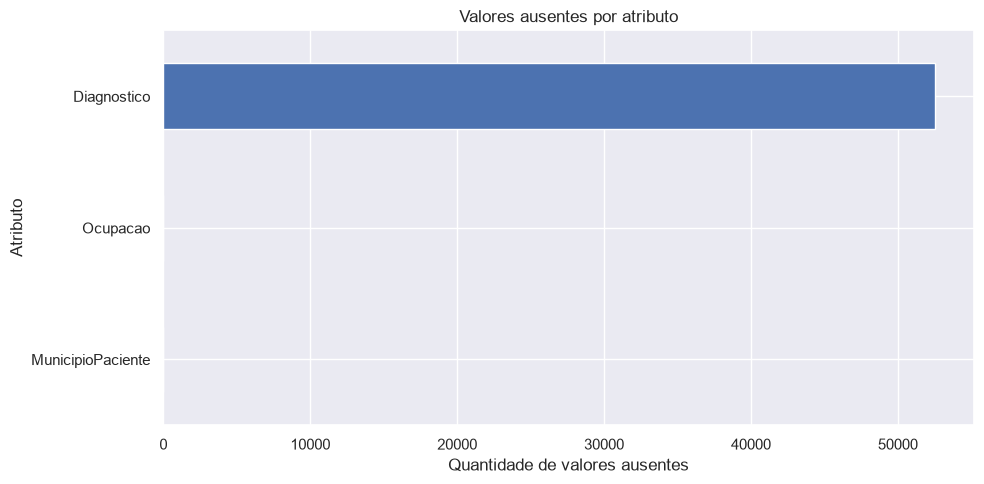

In [9]:
# Seleciona somente as colunas que possuem valores ausentes.
dados = nulos[nulos > 0].sort_values()

# Cria o gráfico de barras horizontais.
dados.plot(
    kind="barh", 
    figsize=(10, 5)
)

plt.title("Valores ausentes por atributo")
plt.xlabel("Quantidade de valores ausentes")
plt.ylabel("Atributo")

plt.tight_layout()
plt.show()

## 8. Indicadores gerais da produção ambulatorial

Distinga **número de registros**, **quantidades de procedimentos apresentadas/aprovadas** e **valores apresentados/aprovados**. 

In [10]:
geral = pd.DataFrame([{
    "Registros": len(tabela),
    "QuantidadeApresentada": tabela["pa_qtdpro"].sum(),
    "QuantidadeAprovada": tabela["pa_qtdapr"].sum(),
    "ValorApresentado": tabela["pa_valpro"].sum(),
    "ValorAprovado": tabela["pa_valapr"].sum()
}])
display(geral)

,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,75192,437815.0,339803.0,5676173.11,5341587.0



## Visualização dos indicadores gerais da produção ambulatorial — gráficos de barras

**Pergunta:** qual é a quantidade total de procedimentos apresentados e aprovados pelo SUS? Qual é a diferença entre os valores financeiros apresentados e aprovados?

**Interpretação:** os gráficos permitem comparar a produção ambulatorial apresentada com a aprovada, tanto em quantidade de procedimentos quanto em valores financeiros. 

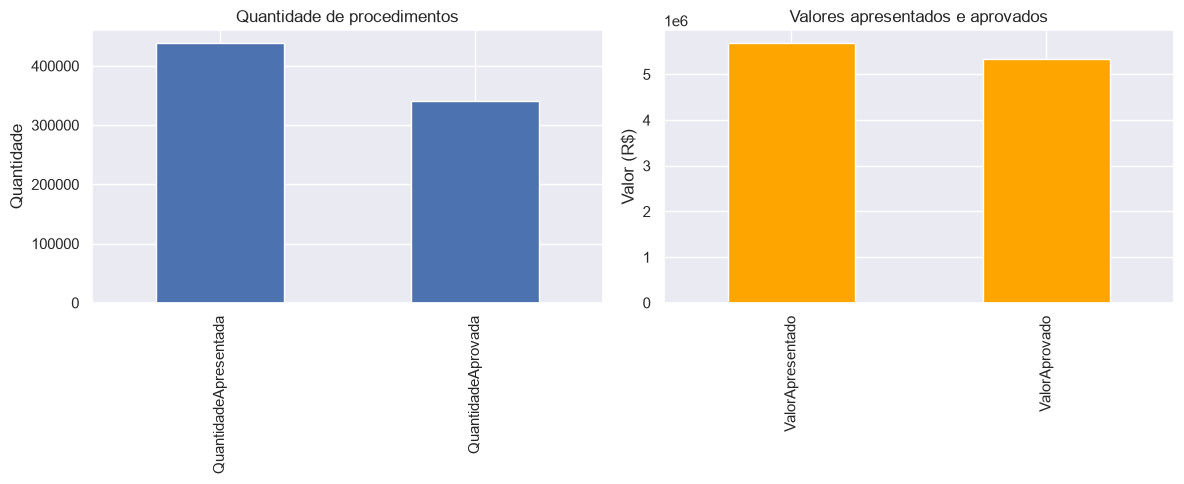

In [11]:
# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: quantidade de procedimentos.
geral[["QuantidadeApresentada", "QuantidadeAprovada"]].T.plot(
    kind="bar", 
    ax=axes[0], 
    legend=False
)
axes[0].set_title("Quantidade de procedimentos")
axes[0].set_ylabel("Quantidade")

# Gráfico 2: valores financeiros.
geral[["ValorApresentado", "ValorAprovado"]].T.plot(
    kind="bar",
    color=["orange", "green"], 
    ax=axes[1], 
    legend=False
)
axes[1].set_title("Valores apresentados e aprovados")
axes[1].set_ylabel("Valor (R$)")

plt.tight_layout()
plt.show()

## 9. Análise temporal - mês

Podemos agrupar **ano + mês**.

In [12]:
mensal = (
    tabela.groupby(["Ano", "Mes"], dropna=False, as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum"))
    .sort_values(["Ano", "Mes"])
)


print("Produção mensal:")
display(mensal)

Produção mensal:


,Ano,Mes,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,2026,8,75192,437815.0,339803.0,5676173.11,5341587.0


## Evolução mensal - gráfico de linhas

**Pergunta:** como evolui a quantidade de procedimentos apresentados e aprovados por mês?

O gráfico de **linhas** é adequado quando o eixo horizontal representa uma sequência temporal ordenada. A tabela vincula `Ano` e `Mes` ao **mês de movimentação (`pa_mvm`)**.

**Cuidado:** se houver apenas dois meses, o gráfico mostra uma comparação pontual; não permite estabelecer tendência de longo prazo.

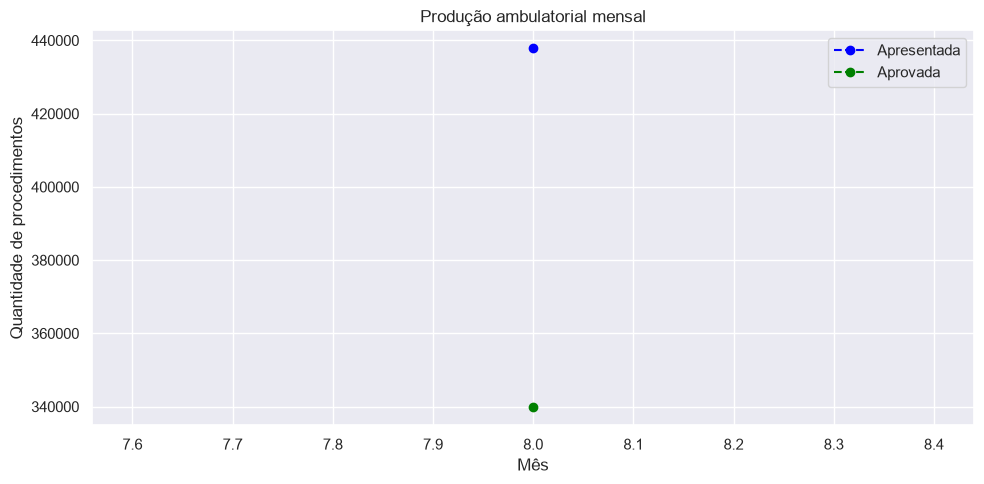

In [13]:
# Cria o gráfico de linhas com os dados calculados na Etapa 2.
mensal.plot(
    x="Mes",
    y=["QuantidadeApresentada", "QuantidadeAprovada"],
    kind="line",
    linestyle="--",
    marker="o",
    color=["blue", "green"],
    figsize=(10, 5)
)

plt.title("Produção ambulatorial mensal")
plt.xlabel("Mês")
plt.ylabel("Quantidade de procedimentos")
plt.legend(["Apresentada", "Aprovada"])
plt.grid(True)

plt.tight_layout()
plt.show()

## Bimestre e trimestre - subplots

**Pergunta:** como a produção se distribui nos bimestres e trimestres?

Aqui os agrupamentos utilizam `AnoBimestre` e `AnoTrimestre` já presentes na tabela.


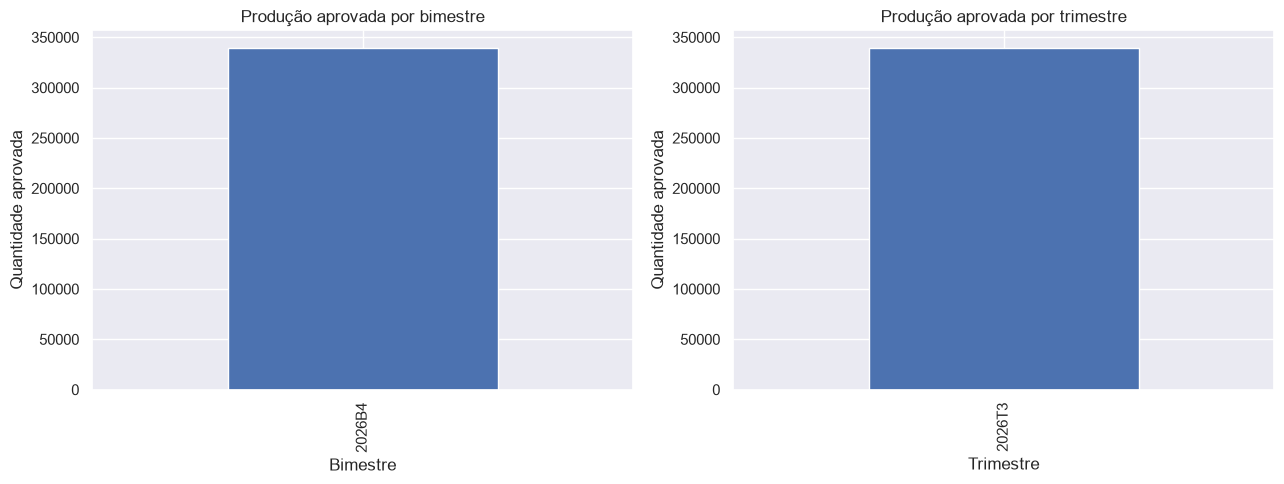

In [14]:
# Agrupa a quantidade aprovada por bimestre e trimestre.
bimestral = tabela.groupby("AnoBimestre")["pa_qtdapr"].sum()
trimestral = tabela.groupby("AnoTrimestre")["pa_qtdapr"].sum()

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico por bimestre.
bimestral.plot(
    kind="bar", 
    ax=axes[0]
)
axes[0].set_title("Produção aprovada por bimestre")
axes[0].set_xlabel("Bimestre")
axes[0].set_ylabel("Quantidade aprovada")

# Gráfico por trimestre.
trimestral.plot(
    kind="bar", 
    ax=axes[1]
)
axes[1].set_title("Produção aprovada por trimestre")
axes[1].set_xlabel("Trimestre")
axes[1].set_ylabel("Quantidade aprovada")

# Exibe os gráficos.
plt.tight_layout()
plt.show()

## 10. Produção por estabelecimento

`Estabelecimento` já contém a descrição na VIEW. 
- `dropna=False`: inclui nos agrupamentos os registros que possuem valores ausentes (`NaN`) na coluna utilizada para agrupar. Por padrão, o Pandas exclui esses grupos (`dropna=True`).
- `as_index=False`: mantém a coluna utilizada no agrupamento como uma coluna normal do DataFrame, em vez de transformá-la em índice.

In [15]:
estabelecimentos = (
    tabela.groupby("Estabelecimento", dropna=False, as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum"))
    .sort_values("QuantidadeAprovada", ascending=False)
)

display(estabelecimentos.head(10))

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,17 COORDENADORIA REGIONAL DE SAUDE,6057,262933.0,198805.0,909578.68,905751.92
9,POSTO CENTRAL SECRETARIA MUNICIPAL DE SAUDE DE...,3169,52110.0,48217.0,458650.70,420921.60
8,HOSPITAL DE CLINICAS IJUI,23620,46109.0,38220.0,3185260.20,3060316.28
6,CISA,1782,31053.0,24976.0,225550.97,165773.67
7,HOSPITAL BOM PASTOR IJUI,30387,30401.0,15403.0,338071.45,242757.25
5,CER III UNIR,4504,4856.0,4428.0,246897.44,240915.04
10,SAE SERVICO DE ATENDIMENTO ESPECIALIZADO,519,3832.0,3523.0,7998.10,6103.20
1,APAE IJUI,2734,2734.0,2445.0,48309.78,43203.15
2,CENTRO AUDITIVO PROAUDI,1931,2408.0,2407.0,253557.59,253546.69
3,CENTRO DE ESPECIALIDADES ODONTOLOGICAS SMS IJUI,362,1213.0,1213.0,1751.70,1751.70


## Visualização da produção por estabelecimento de saúde — barras horizontais

**Pergunta:** quais estabelecimentos apresentam maior quantidade de procedimentos aprovados? Quais possuem as maiores diferenças entre as quantidades apresentadas e aprovadas?

**Interpretação:** os gráficos permitem identificar os estabelecimentos que concentram maior produção ambulatorial e aqueles com maiores diferenças absolutas entre a produção apresentada e a aprovada.

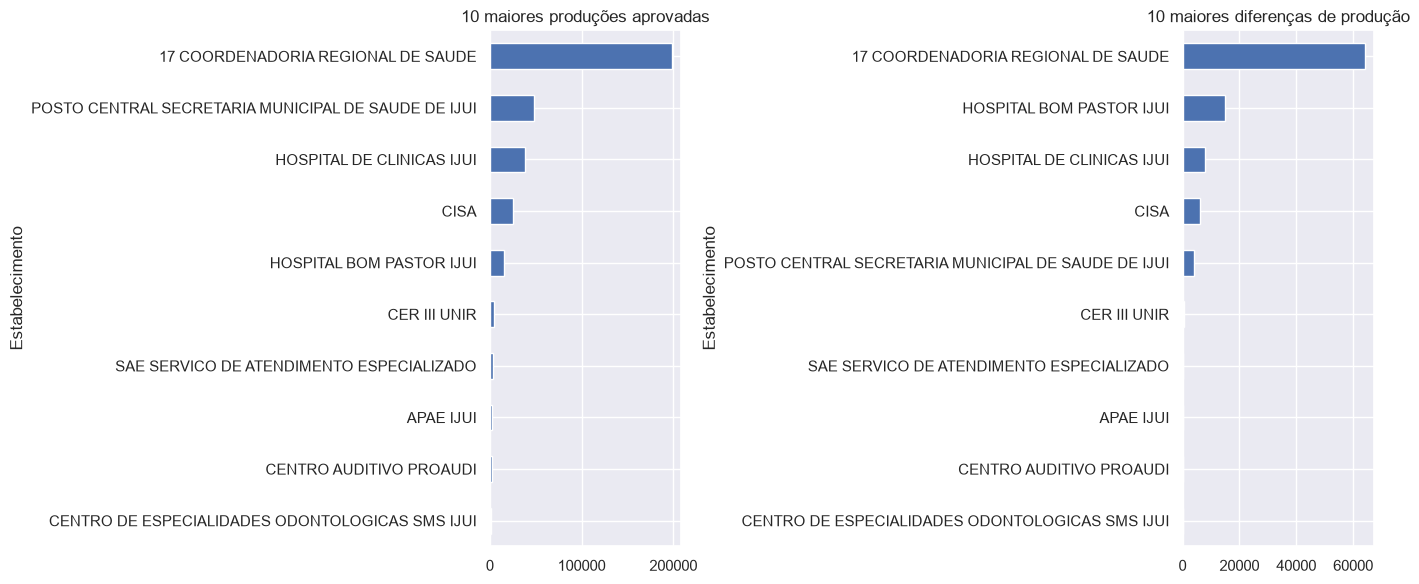

In [16]:
# Calcula a diferença entre quantidades apresentadas e aprovadas.
estabelecimentos["Diferenca"] = (
    estabelecimentos["QuantidadeApresentada"] - estabelecimentos["QuantidadeAprovada"]
)

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 10 estabelecimentos com maior produção aprovada.
estabelecimentos.nlargest(10, "QuantidadeAprovada").sort_values("QuantidadeAprovada", ascending=True).plot(
    x="Estabelecimento", 
    y="QuantidadeAprovada",
    kind="barh", 
    ax=axes[0], 
    legend=False
)
axes[0].set_title("10 maiores produções aprovadas")

# 10 estabelecimentos com maior diferença.
estabelecimentos.nlargest(10, "Diferenca").sort_values("Diferenca", ascending=True).plot(
    x="Estabelecimento", 
    y="Diferenca",
    kind="barh", 
    ax=axes[1], 
    legend=False
)
axes[1].set_title("10 maiores diferenças de produção")

plt.tight_layout()
plt.show()

## 11. Procedimentos e ocupações - comparações por barras

**Pergunta:** quais procedimentos e ocupações concentram a maior produção?

A análise parte das **descrições** disponíveis na tabela. Para manter as comparações legíveis, são exibidas as 10 categorias com maior quantidade aprovada. Descrições ausentes ficam identificadas como **Não informado**.

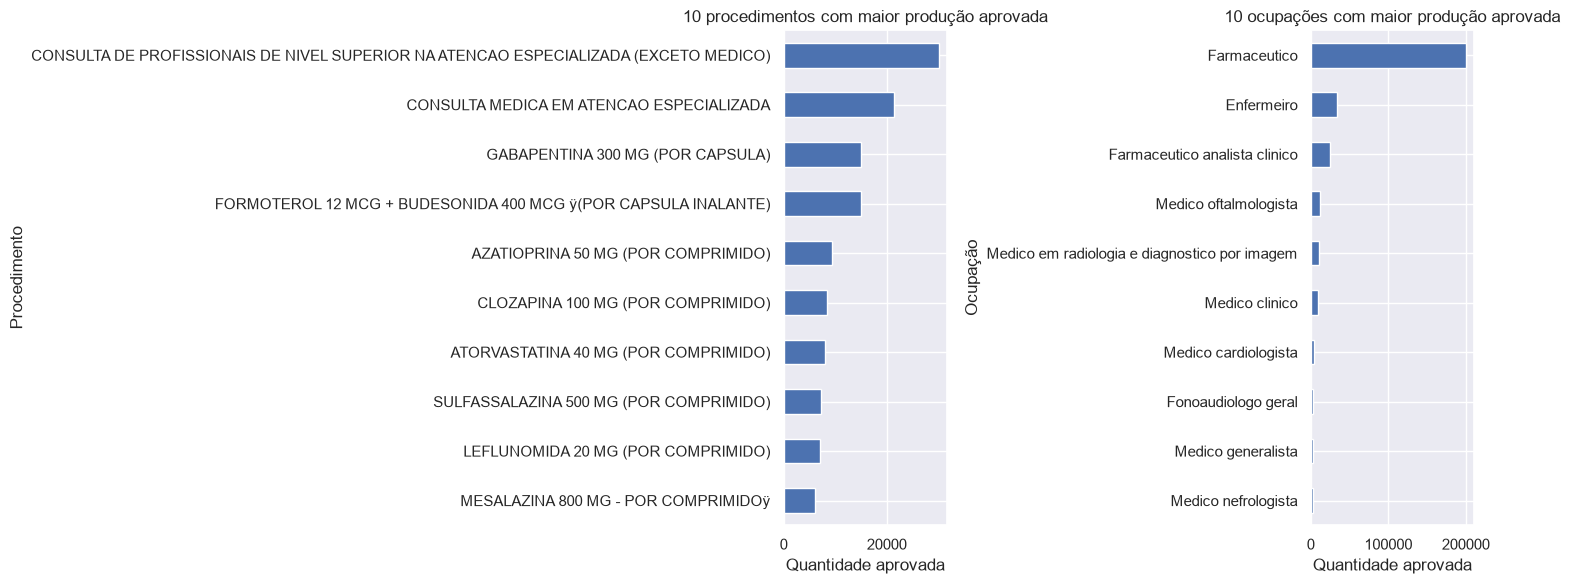

In [17]:
# Calcula a quantidade aprovada por procedimento.
procedimentos = tabela.groupby("Procedimento")["pa_qtdapr"].sum()

# Calcula a quantidade aprovada por ocupação profissional.
ocupacoes = tabela.groupby("Ocupacao")["pa_qtdapr"].sum()

# Seleciona os 10 maiores resultados.
top_procedimentos = procedimentos.nlargest(10).sort_values()
top_ocupacoes = ocupacoes.nlargest(10).sort_values()

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: procedimentos com maior quantidade aprovada.
top_procedimentos.plot(
    kind="barh", 
    ax=axes[0]
)
axes[0].set_title("10 procedimentos com maior produção aprovada")
axes[0].set_xlabel("Quantidade aprovada")
axes[0].set_ylabel("Procedimento")

# Gráfico 2: ocupações com maior quantidade aprovada.
top_ocupacoes.plot(
    kind="barh", 
    ax=axes[1]
)
axes[1].set_title("10 ocupações com maior produção aprovada")
axes[1].set_xlabel("Quantidade aprovada")
axes[1].set_ylabel("Ocupação")

# Ajusta e exibe os gráficos.
plt.tight_layout()
plt.show()

## 12. Perfil demográfico - barras e histograma

**Pergunta:** como se distribuem os registros com informação disponível por sexo e idade?

- **Barras:** distribuição de frequências por categoria de sexo, preservando os códigos encontrados na base (sem pressupor que sejam apenas `M`/`F`).
- **Histograma:** distribuição de idades em intervalos (*bins*).

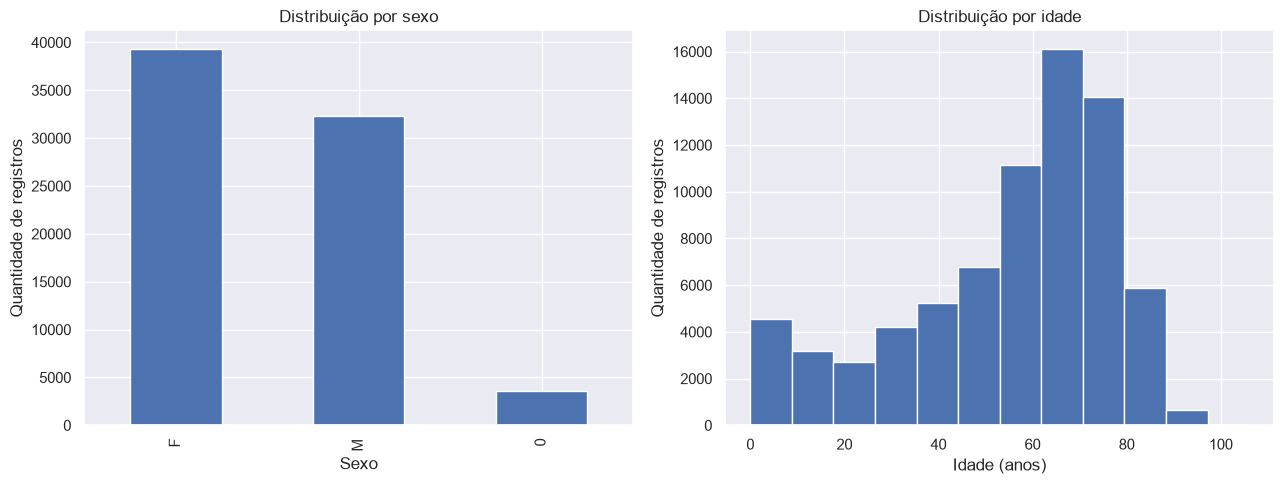

In [18]:
# Calcula a frequência dos registros por sexo.
sexo = tabela["pa_sexo"].value_counts()

# Converte as idades para valores numéricos.
idades = pd.to_numeric(tabela["pa_idade"])

# Considera somente idades entre 0 e 120 anos.
idades = idades[idades.between(0, 120)]

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: distribuição por sexo.
sexo.plot(
    kind="bar", 
    ax=axes[0]
)
axes[0].set_title("Distribuição por sexo")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Quantidade de registros")

# Gráfico 2: distribuição das idades.
idades.plot(
    kind="hist", 
    bins=12, 
    ax=axes[1]
)
axes[1].set_title("Distribuição por idade")
axes[1].set_xlabel("Idade (anos)")
axes[1].set_ylabel("Quantidade de registros")

# Ajusta e exibe os gráficos.
plt.tight_layout()
plt.show()

## 13. Perfil demográfico - heatmap com Seaborn

`sns.heatmap()` destaca padrões em uma matriz. Aqui, a matriz relaciona **faixas etárias × códigos de sexo**, contando **registros** com informações disponíveis.

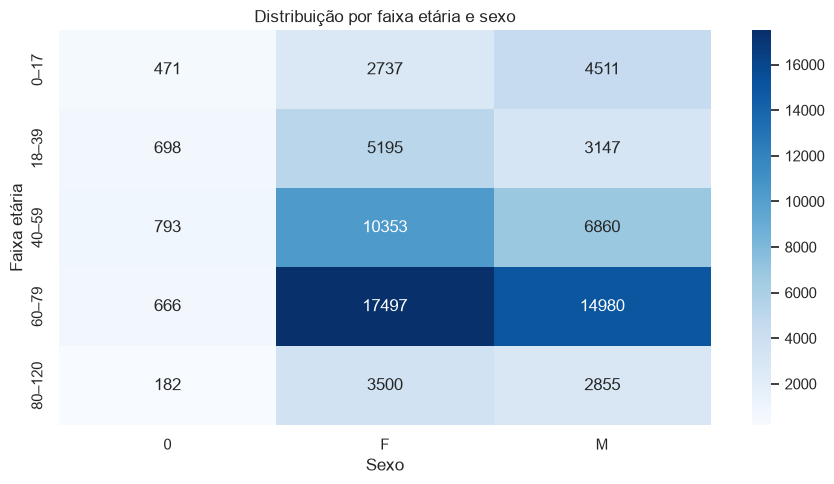

In [19]:
# Organiza as idades em faixas etárias.
faixas = pd.cut(
    idades,
    bins=[-1, 17, 39, 59, 79, 120],
    labels=["0–17", "18–39", "40–59", "60–79", "80–120"]
)

# Conta os registros por faixa etária e sexo.
matriz = pd.crosstab(faixas, tabela["pa_sexo"])

# Cria o mapa de calor.
plt.figure(figsize=(9, 5))

sns.heatmap(
    matriz, 
    annot=True, 
    fmt="d", 
    cmap="Blues"
)

plt.title("Distribuição por faixa etária e sexo")
plt.xlabel("Sexo")
plt.ylabel("Faixa etária")

plt.tight_layout()
plt.show()

## 14. Diagnósticos informados - gráfico de barras

**Pergunta:** quais diagnósticos aparecem mais frequentemente nos registros com CID10 informado?

A contagem utiliza **registros**, não pacientes distintos. 

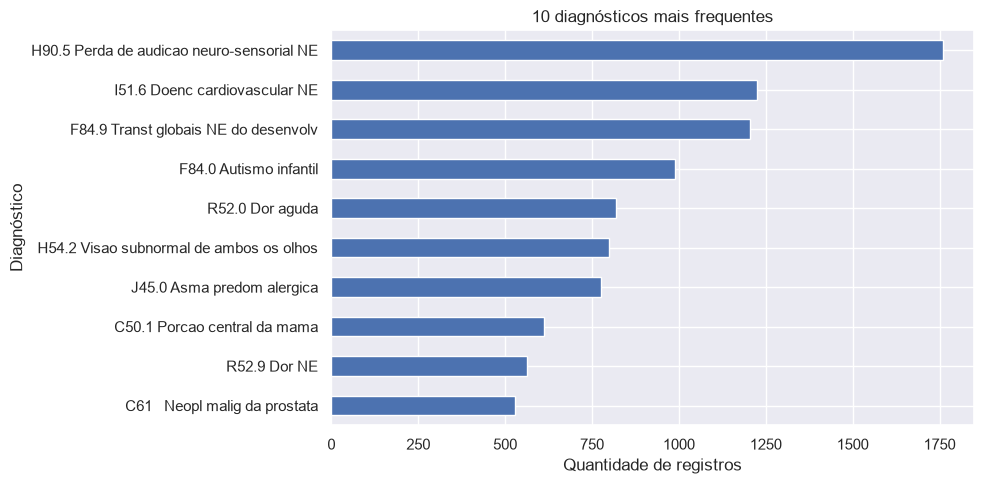

In [20]:
# Seleciona os registros que possuem CID principal informado.
dados = tabela[
    tabela["pa_cidpri"].notna() &
    ~tabela["pa_cidpri"].isin(["", "0000"])
]

# Conta os registros por diagnóstico.
diagnosticos = dados["Diagnostico"].value_counts()

# Seleciona os 10 diagnósticos mais frequentes.
top_diagnosticos = diagnosticos.head(10).sort_values()

# Cria o gráfico de barras horizontais.
top_diagnosticos.plot(
    kind="barh", 
    figsize=(10, 5)
)

plt.title("10 diagnósticos mais frequentes")
plt.xlabel("Quantidade de registros")
plt.ylabel("Diagnóstico")

plt.tight_layout()
plt.show()

## 15. Fluxos regionais - municípios informados nos registros

**Pergunta:** quais municípios aparecem no campo `MunicipioPaciente` e qual parcela dos registros informa município diferente de Ijuí?

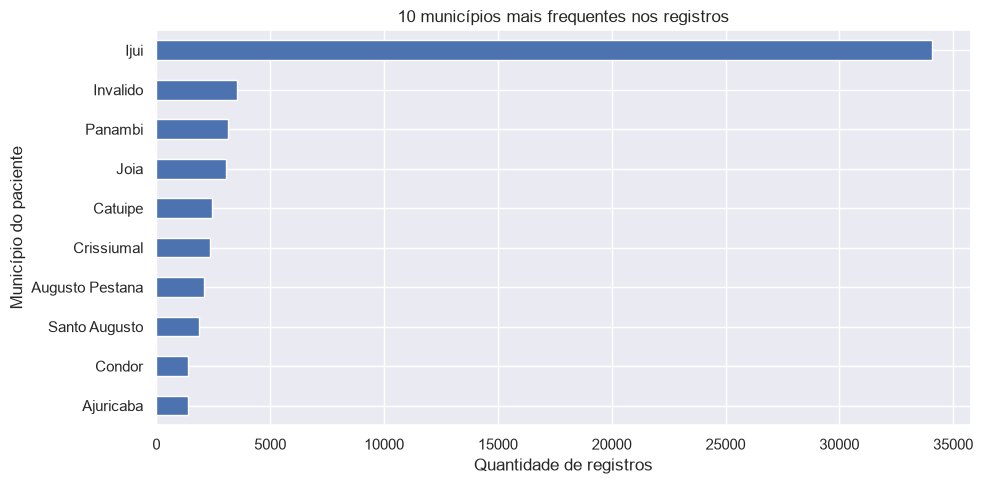

In [21]:
# Conta os registros por município do paciente.
municipios = tabela["MunicipioPaciente"].value_counts()

# Seleciona os 10 municípios com mais registros.
top_municipios = municipios.head(10).sort_values()

# Cria o gráfico de barras horizontais.
top_municipios.plot(
    kind="barh", 
    figsize=(10, 5)
)

plt.title("10 municípios mais frequentes nos registros")
plt.xlabel("Quantidade de registros")
plt.ylabel("Município do paciente")

plt.tight_layout()
plt.show()

## Comandos úteis no Pandas

| Comando | Aplicação |
|---|---|
| `pd.DataFrame()` | Carregar resultado da VIEW |
| `.shape`, `.dtypes`, `.head()`, `.tail()` | Exploração estrutural |
| `.loc[]`, `.iloc[]` | Seleção de linhas e colunas |
| `pd.to_numeric()` | Preparar variáveis numéricas |
| `.describe()`, `.median()`, `.value_counts()` | Estatística descritiva |
| `.isna()`, `.duplicated()`, `.dropna()` | Qualidade e limpeza (sem exclusão automática) |
| `.groupby().agg()` | Agregação por tempo, estabelecimento, procedimento e perfil |
| `.sort_values()`, `.head()` | Rankings |
| `.diff()`, `.pct_change()` | Variação temporal |
| `.str.contains()` | Triagem textual exploratória |
| `pd.cut()` | Construção de faixas etárias |

## Comandos úteis de visualização

| Comando | Aplicação |
|---|---|
| `fig, ax = plt.subplots()` | Criar figuras e eixos |
| `ax.bar()` / `ax.barh()` | Comparar estabelecimentos, procedimentos e municípios |
| `ax.plot()` | Representar séries mensais e indicadores financeiros |
| `ax.hist()` | Explorar a distribuição das idades |
| `sns.boxplot()` | Explorar a dispersão das quantidades por registro |
| `sns.heatmap()` | Representar frequências por idade e sexo |
| `plt.tight_layout()` / `plt.show()` | Organizar e apresentar figuras |

**Ordem de execução:** Etapa 2 completa → configuração de Matplotlib e Seaborn → gráficos e interpretações da Etapa 3.


## Célula A — Análise e Gráfico das Áreas Críticas 
## (Oncologia, Saúde Mental e Atenção Básica)

,Area,QtdAprovada,ValorAprovado
0,Oncologia,766.0,1381796.12
1,Saúde Mental,35035.0,62751.32
2,Atenção Básica,48292.0,420921.60


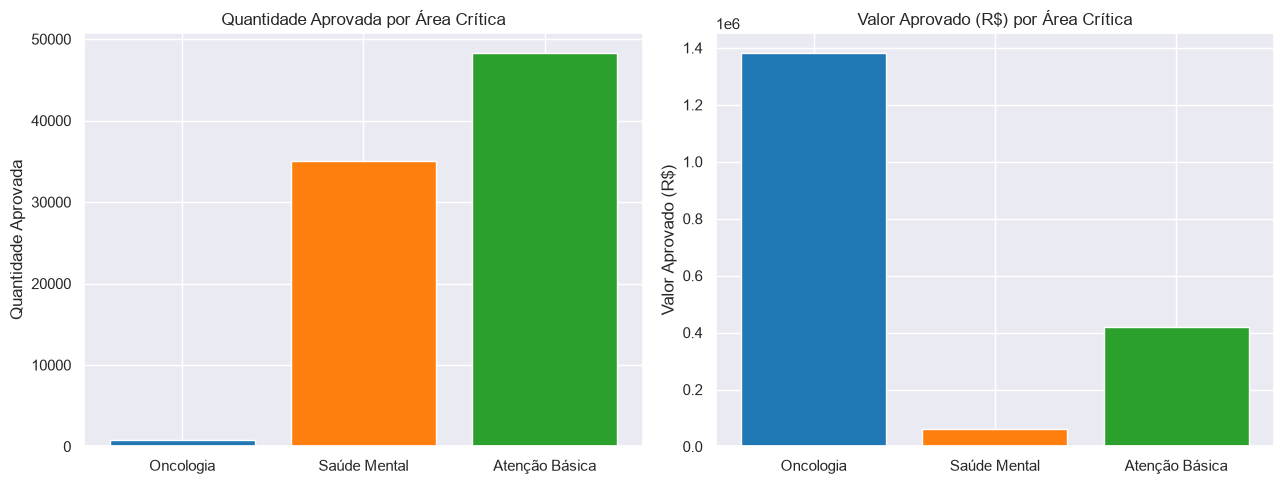

In [22]:
# Triagem textual exploratória das áreas críticas (.str.contains)
filtro_onco = tabela["Procedimento"].str.contains("QUIMIOTERAPIA|RADIOTERAPIA|ONCOLOG", case=False, na=False)
filtro_mental = (
    tabela["pa_cidpri"].astype(str).str.startswith("F") |
    tabela["Ocupacao"].str.contains("PSIQUIATR|PSICOLOG", case=False, na=False) |
    tabela["Estabelecimento"].str.contains("CAPS", case=False, na=False)
)
filtro_ab = (
    tabela["Procedimento"].str.contains("ATENCAO BASICA", case=False, na=False) |
    tabela["Estabelecimento"].str.contains("POSTO|UBS|ESF|SAUDE DA FAMILIA", case=False, na=False)
)

areas_criticas = pd.DataFrame([
    {"Area": "Oncologia", "QtdAprovada": tabela.loc[filtro_onco, "pa_qtdapr"].sum(), "ValorAprovado": tabela.loc[filtro_onco, "pa_valapr"].sum()},
    {"Area": "Saúde Mental", "QtdAprovada": tabela.loc[filtro_mental, "pa_qtdapr"].sum(), "ValorAprovado": tabela.loc[filtro_mental, "pa_valapr"].sum()},
    {"Area": "Atenção Básica", "QtdAprovada": tabela.loc[filtro_ab, "pa_qtdapr"].sum(), "ValorAprovado": tabela.loc[filtro_ab, "pa_valapr"].sum()}
])

display(areas_criticas)

# Visualização das Áreas Críticas (fig, ax = plt.subplots e ax.bar)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].bar(areas_criticas["Area"], areas_criticas["QtdAprovada"], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax[0].set_title("Quantidade Aprovada por Área Crítica")
ax[0].set_ylabel("Quantidade Aprovada")

ax[1].bar(areas_criticas["Area"], areas_criticas["ValorAprovado"], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax[1].set_title("Valor Aprovado (R$) por Área Crítica")
ax[1].set_ylabel("Valor Aprovado (R$)")

plt.tight_layout()
plt.show()

## Célula B — Análise Financeira e Dispersão (ax.bar() e sns.boxplot())

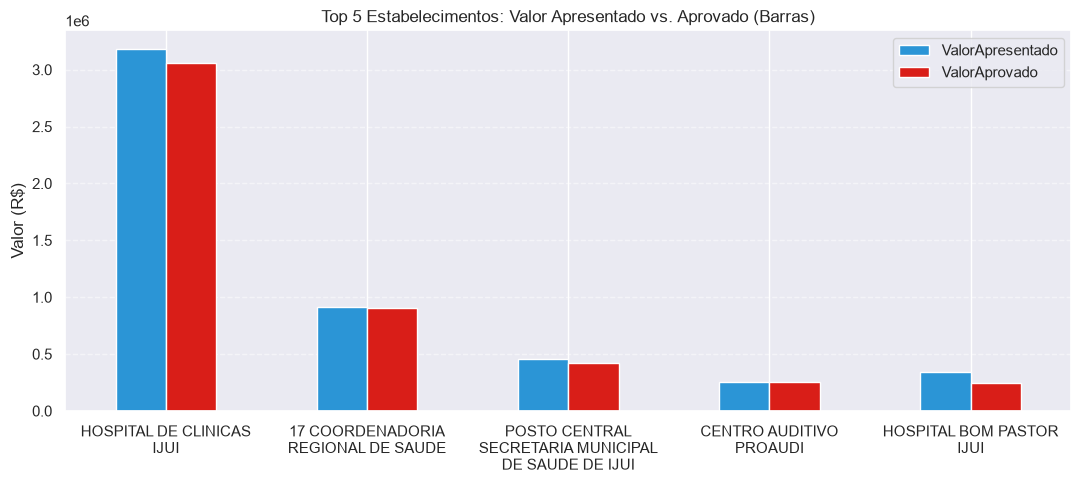

In [30]:
import textwrap

# Prepara os dados (Top 5 em Valor Aprovado)
top_fin = estabelecimentos.nlargest(5, "ValorAprovado").copy()

# Quebra nomes muito longos em duas linhas para ficarem 100% legíveis
nomes_organizados = [textwrap.fill(nome, width=22) for nome in top_fin["Estabelecimento"]]

fig, ax = plt.subplots(figsize=(11, 5))

top_fin.plot(
    x="Estabelecimento",
    y=["ValorApresentado", "ValorAprovado"],
    kind="bar",
    ax=ax,
    color=["#2B95D6", "#D91E18"]
)

ax.set_title("Top 5 Estabelecimentos: Valor Apresentado vs. Aprovado (Barras)")
ax.set_xlabel("")
ax.set_ylabel("Valor (R$)")
ax.set_xticklabels(nomes_organizados, rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Volume e Especialidades


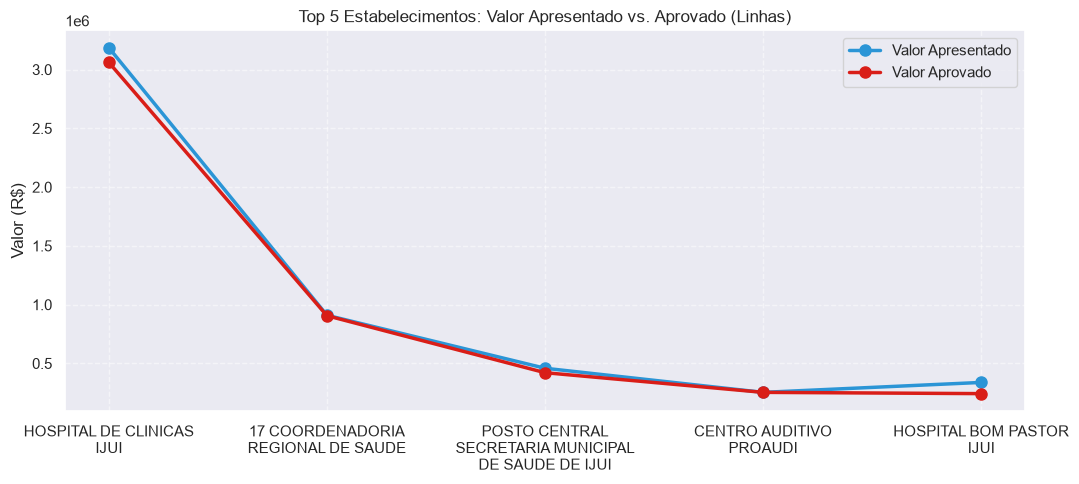

In [31]:
import textwrap

# Prepara os dados (Top 5 em Valor Aprovado)
top_fin = estabelecimentos.nlargest(5, "ValorAprovado").copy()

# Quebra nomes muito longos em duas linhas para ficarem 100% legíveis
nomes_organizados = [textwrap.fill(nome, width=22) for nome in top_fin["Estabelecimento"]]

fig, ax = plt.subplots(figsize=(11, 5))

# Linha Azul (Valor Apresentado)
ax.plot(
    nomes_organizados, top_fin["ValorApresentado"],
    marker="o", markersize=8, linewidth=2.5, color="#2B95D6", label="Valor Apresentado"
)

# Linha Vermelha (Valor Aprovado)
ax.plot(
    nomes_organizados, top_fin["ValorAprovado"],
    marker="o", markersize=8, linewidth=2.5, color="#D91E18", label="Valor Aprovado"
)

ax.set_title("Top 5 Estabelecimentos: Valor Apresentado vs. Aprovado (Linhas)")
ax.set_ylabel("Valor (R$)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Perfil Demográfico e Epidemiológico

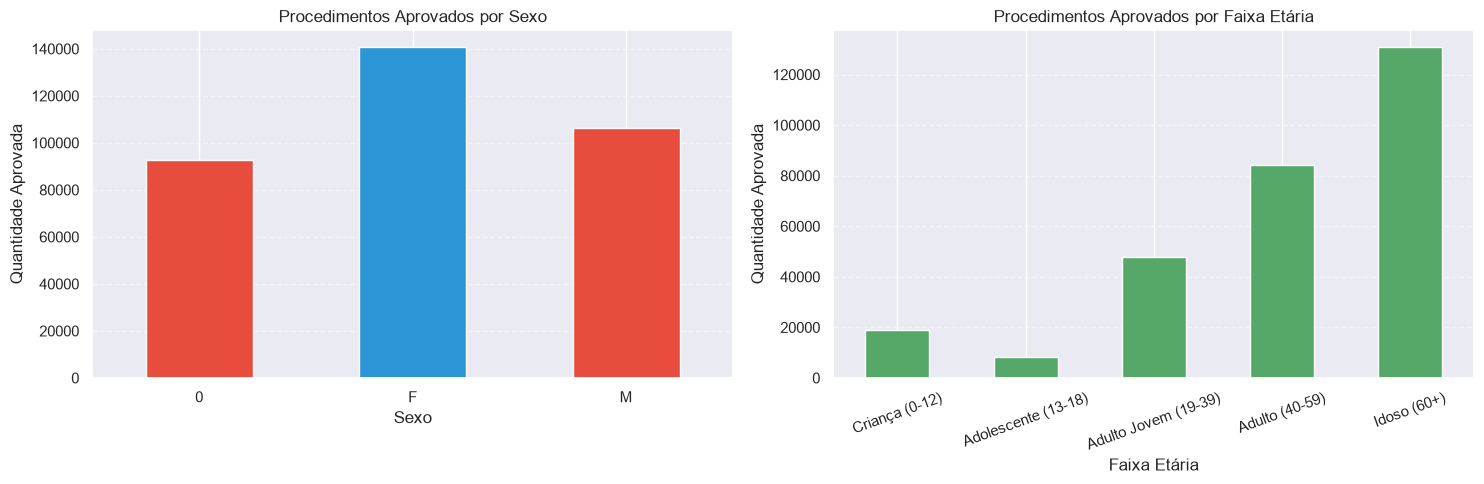

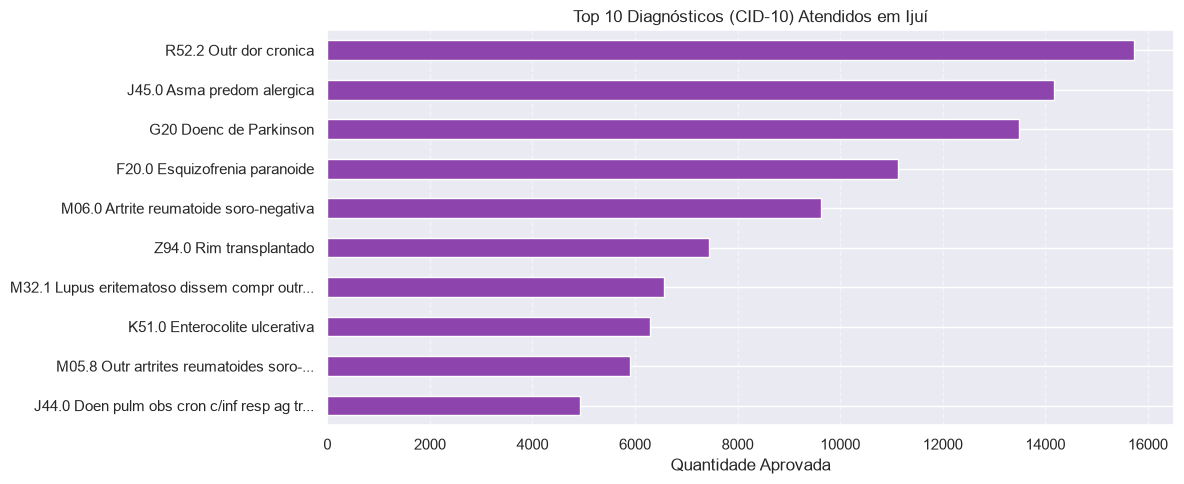

In [42]:
import pandas as pd
import textwrap

# Cria faixas etárias a partir da coluna pa_idade
bins = [0, 12, 18, 39, 59, 120]
labels = ["Criança (0-12)", "Adolescente (13-18)", "Adulto Jovem (19-39)", "Adulto (40-59)", "Idoso (60+)"]
tabela["FaixaEtaria"] = pd.cut(pd.to_numeric(tabela["pa_idade"], errors="coerce"), bins=bins, labels=labels, right=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Distribuição por Sexo
sexo_counts = tabela.groupby("pa_sexo")["pa_qtdapr"].sum()
sexo_counts.plot(kind="bar", ax=ax[0], color=["#E74C3C", "#2B95D6"])
ax[0].set_title("Procedimentos Aprovados por Sexo")
ax[0].set_xlabel("Sexo")
ax[0].set_ylabel("Quantidade Aprovada")
ax[0].tick_params(axis="x", rotation=0)
ax[0].grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico 2: Distribuição por Faixa Etária
faixa_counts = tabela.groupby("FaixaEtaria", observed=False)["pa_qtdapr"].sum()
faixa_counts.plot(kind="bar", ax=ax[1], color="#55A868")
ax[1].set_title("Procedimentos Aprovados por Faixa Etária")
ax[1].set_xlabel("Faixa Etária")
ax[1].set_ylabel("Quantidade Aprovada")
ax[1].tick_params(axis="x", rotation=20)
ax[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Gráfico 3: Top 10 Diagnósticos (CID-10)
top_diag = (
    tabela[tabela["Diagnostico"].notna() & (tabela["Diagnostico"] != "")]
    .groupby("Diagnostico")["pa_qtdapr"]
    .sum()
    .nlargest(10)
    .sort_values(ascending=True)
)
top_diag.index = [textwrap.shorten(d, width=45, placeholder="...") for d in top_diag.index]

fig, ax = plt.subplots(figsize=(12, 5))
top_diag.plot(kind="barh", ax=ax, color="#8E44AD")
ax.set_title("Top 10 Diagnósticos (CID-10) Atendidos em Ijuí")
ax.set_xlabel("Quantidade Aprovada")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Fluxos Regionais e Acesso

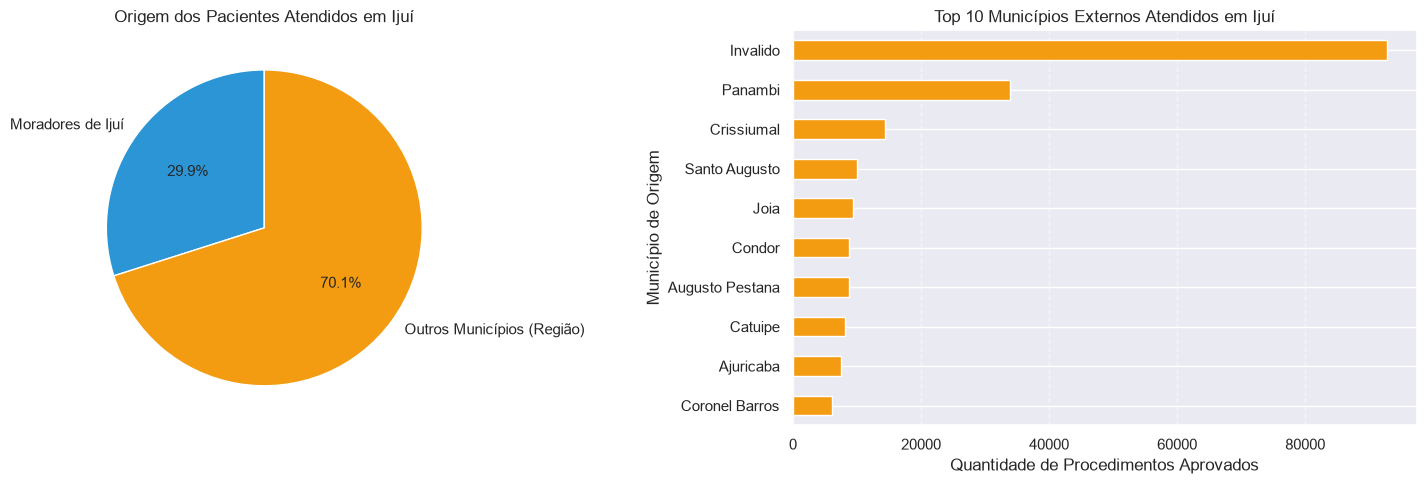

Resumo Numérico de Fluxo Regional (Procedimentos Aprovados):
Origem_Paciente
Moradores de Ijuí             101650.0
Outros Municípios (Região)    238153.0
Name: pa_qtdapr, dtype: float64


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Separa moradores de Ijuí vs. Outros Municípios de forma vetorizada (evita erro de tipo/nulo)
eh_ijui = tabela["MunicipioPaciente"].astype(str).str.upper().str.contains("IJUI|IJUÍ|431020", na=False)
tabela["Origem_Paciente"] = np.where(eh_ijui, "Moradores de Ijuí", "Outros Municípios (Região)")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Proporção Local vs. Regional
fluxo_geral = tabela.groupby("Origem_Paciente")["pa_qtdapr"].sum()
fluxo_geral.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2B95D6", "#F39C12"],
    ax=ax[0],
    textprops={"fontsize": 11}
)
ax[0].set_title("Origem dos Pacientes Atendidos em Ijuí")
ax[0].set_ylabel("")

# Gráfico 2: Top 10 Municípios Externos que buscam atendimento em Ijuí
outros_mun = tabela[tabela["Origem_Paciente"] == "Outros Municípios (Região)"]
top_municipios = (
    outros_mun.groupby("MunicipioPaciente")["pa_qtdapr"]
    .sum()
    .nlargest(10)
    .sort_values(ascending=True)
)

top_municipios.plot(kind="barh", ax=ax[1], color="#F39C12")
ax[1].set_title("Top 10 Municípios Externos Atendidos em Ijuí")
ax[1].set_xlabel("Quantidade de Procedimentos Aprovados")
ax[1].set_ylabel("Município de Origem")
ax[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("Resumo Numérico de Fluxo Regional (Procedimentos Aprovados):")
print(fluxo_geral)

## Foco em Áreas Critícas

As áreas de Oncologia, Saúde Mental e Atenção Básica


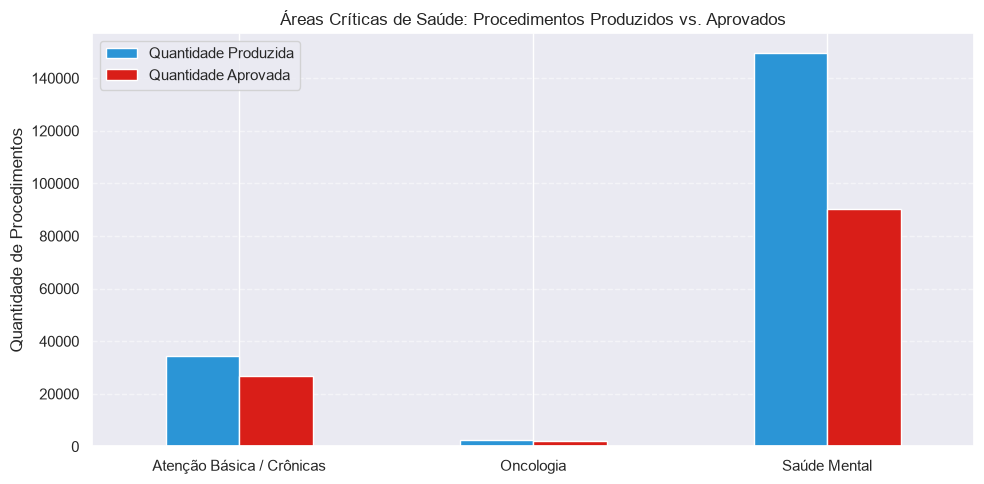

                           pa_qtdpro  pa_qtdapr
AreaCritica                                    
Atenção Básica / Crônicas    34512.0    26844.0
Oncologia                     2305.0     2241.0
Saúde Mental                149547.0    90349.0


In [ ]:
def classificar_area(row):
    cid = str(row["pa_cidpri"]).upper()
    proc = str(row["Procedimento"]).upper()
    
    # Oncologia: CIDs iniciados com C (Neoplasias) ou procedimentos de quimio/radioterapia
    if cid.startswith("C") or "QUIMIOTERAPIA" in proc or "RADIOTERAPIA" in proc or "ONCOLOG" in proc:
        return "Oncologia"
    # Saúde Mental: CIDs iniciados com F (Transtornos mentais) ou psiquiatria/psicologia
    elif cid.startswith("F") or "PSIQUIATR" in proc or "PSICOLOG" in proc or "CAPS" in proc:
        return "Saúde Mental"
    # Atenção Básica: Consultas básicas, hipertensão (I10-I15), diabetes (E10-E14)
    elif cid.startswith(("I10", "I11", "E10", "E11", "E14")) or "ATENCAO BASICA" in proc or "CONSULTA MEDICA EM ATENCAO" in proc:
        return "Atenção Básica / Crônicas"
    else:
        return "Outras Especialidades"

tabela["AreaCritica"] = tabela.apply(classificar_area, axis=1)

# Filtra apenas as 3 áreas críticas exigidas no trabalho
areas_foco = tabela[tabela["AreaCritica"] != "Outras Especialidades"]
resumo_areas = areas_foco.groupby("AreaCritica")[["pa_qtdpro", "pa_qtdapr"]].sum()

fig, ax = plt.subplots(figsize=(10, 5))
resumo_areas.plot(kind="bar", ax=ax, color=["#2B95D6", "#D91E18"])

ax.set_title("Áreas Críticas de Saúde: Procedimentos Produzidos vs. Aprovados")
ax.set_xlabel("")
ax.set_ylabel("Quantidade de Procedimentos")
ax.legend(["Quantidade Produzida", "Quantidade Aprovada"])
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print(resumo_areas)